# Análisis de WikiText-103 train.raw

Objetivo: analizar los ~30K artículos del archivo de entrenamiento para seleccionar **1,000 artículos representativos** que cubran diversidad de tamaños y temas para el pipeline de traducción.

## Contenido
1. Carga y split de artículos
2. Distribución de longitudes (palabras y caracteres)
3. Clasificación temática automática (heurística por keywords)
4. Estadísticas de estructura (secciones por artículo)
5. Criterios de selección y generación del subset

In [1]:
import re
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (12, 5)})

RAW_FILE = Path("../data/WikiText/wikitext-103-raw.wiki.train.raw")
print(f"Archivo: {RAW_FILE}")
print(f"Tamaño: {RAW_FILE.stat().st_size / (1024**2):.1f} MB")

Archivo: ../data/WikiText/wikitext-103-raw.wiki.train.raw
Tamaño: 515.5 MB


## 1. Carga y split de artículos

Dividimos el archivo usando el patrón de títulos nivel 1 de WikiText: `= Título =`

In [2]:
texto = RAW_FILE.read_text(encoding="utf-8")

# Split por títulos nivel 1: " = Título = "
pattern = r'(?=^ = [^=].+[^=] = $)'
partes = re.split(pattern, texto, flags=re.MULTILINE)
articulos_raw = [p.strip() for p in partes if p.strip()]

print(f"Total de artículos: {len(articulos_raw):,}")
print(f"Caracteres totales: {len(texto):,}")

# Extraer título de cada artículo
def extraer_titulo(art: str) -> str:
    match = re.match(r'^ = (.+?) = $', art, flags=re.MULTILINE)
    return match.group(1).strip() if match else "(sin título)"

# Construir DataFrame
data = []
for i, art in enumerate(articulos_raw, 1):
    titulo = extraer_titulo(art)
    palabras = len(art.split())
    chars = len(art)
    # Contar secciones nivel 2
    secciones = len(re.findall(r'^ = = .+? = = $', art, flags=re.MULTILINE))
    data.append({
        "id": i,
        "titulo": titulo,
        "palabras": palabras,
        "caracteres": chars,
        "secciones": secciones,
        "lineas": art.count("\n") + 1,
    })

df = pd.DataFrame(data)
print(f"\nDataFrame creado: {df.shape}")
df.head(10)

Total de artículos: 29,423
Caracteres totales: 539,566,975

DataFrame creado: (29423, 6)


,id,titulo,palabras,caracteres,secciones,lineas
0,1,(sin título),3772,20939,8,48
1,2,(sin título),3932,21506,5,80
2,3,(sin título),3069,16224,16,136
3,4,(sin título),681,3674,2,14
4,5,(sin título),1311,6986,5,27
5,6,(sin título),3445,17860,12,62
6,7,(sin título),10,39,0,2
7,8,(sin título),8,29,0,2
8,9,(sin título),25,99,1,6
9,10,(sin título),14,52,0,2


## 2. Estadísticas descriptivas

In [3]:
print("=" * 60)
print("ESTADÍSTICAS GENERALES")
print("=" * 60)
print(f"Total artículos:        {len(df):,}")
print(f"Total palabras:         {df['palabras'].sum():,}")
print(f"Total caracteres:       {df['caracteres'].sum():,}")
print()
print(df[["palabras", "caracteres", "secciones", "lineas"]].describe().round(1).to_string())
print()
print("─" * 60)
print("PERCENTILES DE PALABRAS")
print("─" * 60)
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    val = df["palabras"].quantile(p / 100)
    print(f"  P{p:>2}: {val:>8,.0f} palabras")

ESTADÍSTICAS GENERALES
Total artículos:        29,423
Total palabras:         101,425,671
Total caracteres:       539,356,635

       palabras  caracteres  secciones   lineas
count   29423.0     29423.0    29423.0  29423.0
mean     3447.2     18331.1        9.2     59.1
std      2805.2     15143.3        7.4     46.0
min         5.0        21.0        0.0      2.0
25%      1549.5      8141.0        4.0     28.0
50%      2579.0     13598.0        7.0     46.0
75%      4461.5     23714.5       12.0     75.0
max     30917.0    157629.0      111.0    720.0

────────────────────────────────────────────────────────────
PERCENTILES DE PALABRAS
────────────────────────────────────────────────────────────
  P 1:       17 palabras
  P 5:      728 palabras
  P10:      993 palabras
  P25:    1,550 palabras
  P50:    2,579 palabras
  P75:    4,462 palabras
  P90:    7,121 palabras
  P95:    9,212 palabras
  P99:   13,511 palabras


## 3. Distribución de longitudes

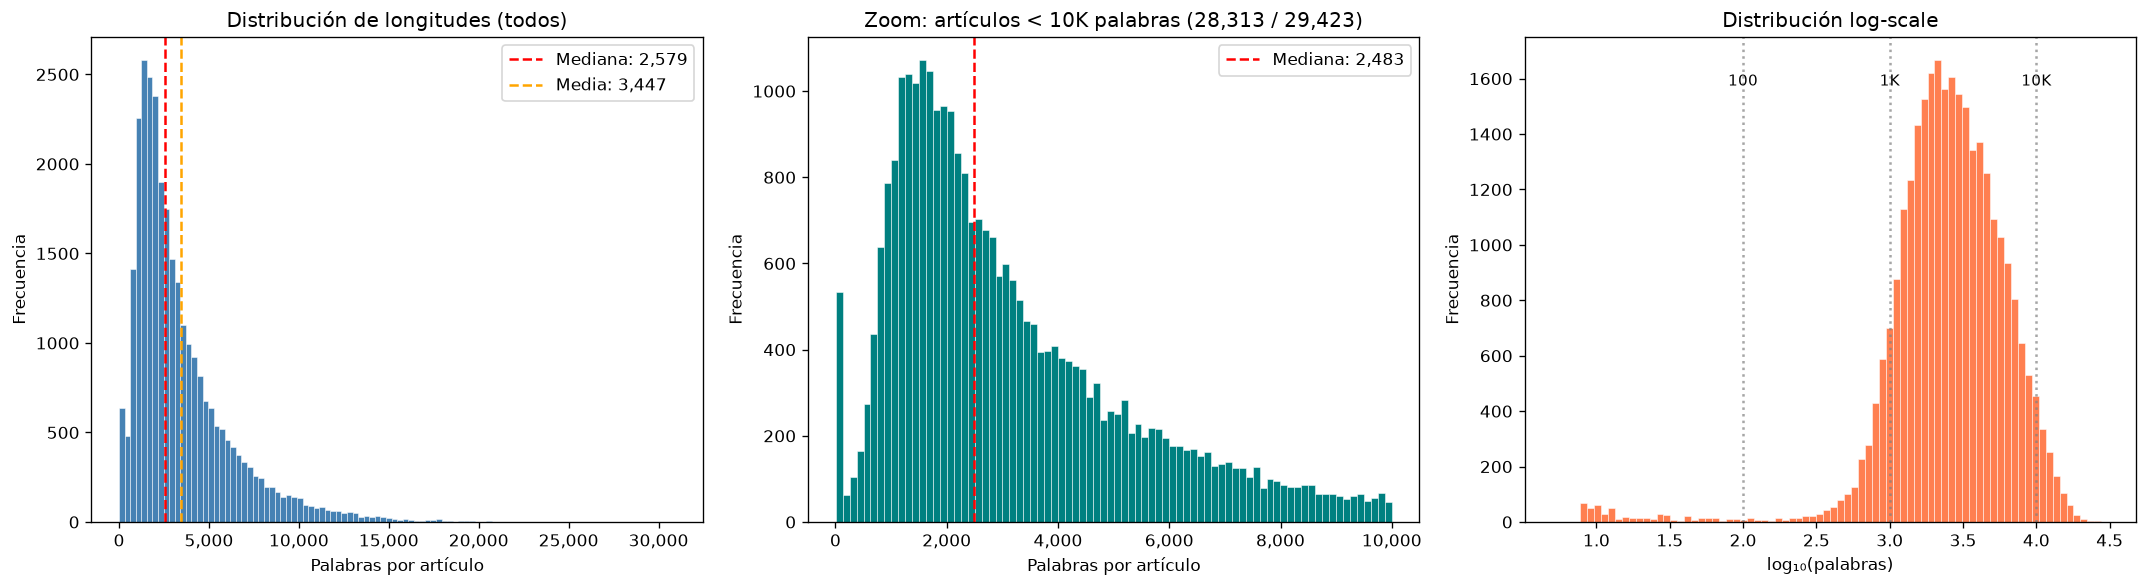

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 3a. Histograma general de palabras
ax = axes[0]
ax.hist(df["palabras"], bins=100, color="steelblue", edgecolor="white", linewidth=0.3)
ax.set_xlabel("Palabras por artículo")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución de longitudes (todos)")
ax.axvline(df["palabras"].median(), color="red", linestyle="--", label=f'Mediana: {df["palabras"].median():,.0f}')
ax.axvline(df["palabras"].mean(), color="orange", linestyle="--", label=f'Media: {df["palabras"].mean():,.0f}')
ax.legend()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# 3b. Histograma zoom (< 10K palabras = mayoría)
ax = axes[1]
subset = df[df["palabras"] < 10000]
ax.hist(subset["palabras"], bins=80, color="teal", edgecolor="white", linewidth=0.3)
ax.set_xlabel("Palabras por artículo")
ax.set_ylabel("Frecuencia")
ax.set_title(f"Zoom: artículos < 10K palabras ({len(subset):,} / {len(df):,})")
ax.axvline(subset["palabras"].median(), color="red", linestyle="--", label=f'Mediana: {subset["palabras"].median():,.0f}')
ax.legend()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# 3c. Distribución log-scale
ax = axes[2]
ax.hist(np.log10(df["palabras"].clip(lower=1)), bins=80, color="coral", edgecolor="white", linewidth=0.3)
ax.set_xlabel("log₁₀(palabras)")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución log-scale")
# Marcar rangos útiles
for val, label in [(2, "100"), (3, "1K"), (4, "10K")]:
    ax.axvline(val, color="gray", linestyle=":", alpha=0.7)
    ax.text(val, ax.get_ylim()[1] * 0.9, label, ha="center", fontsize=9)

plt.tight_layout()
plt.show()

In [5]:
# Tabla de rangos de tamaño
bins = [0, 100, 300, 500, 1000, 2000, 5000, 10000, 20000, 50000, float("inf")]
labels = ["<100", "100-300", "300-500", "500-1K", "1K-2K", "2K-5K", "5K-10K", "10K-20K", "20K-50K", "50K+"]
df["rango_palabras"] = pd.cut(df["palabras"], bins=bins, labels=labels, right=False)

tabla_rangos = df.groupby("rango_palabras", observed=False).agg(
    articulos=("id", "count"),
    palabras_total=("palabras", "sum"),
    media_palabras=("palabras", "mean"),
).reset_index()
tabla_rangos["pct_articulos"] = (tabla_rangos["articulos"] / len(df) * 100).round(1)
tabla_rangos["pct_palabras"] = (tabla_rangos["palabras_total"] / df["palabras"].sum() * 100).round(1)

print("DISTRIBUCIÓN POR RANGO DE TAMAÑO")
print("=" * 80)
print(tabla_rangos.to_string(index=False))
print()
print("Nota: para traducción, artículos muy cortos (<100 palabras) aportan poco contexto.")
print("      Artículos muy largos (>10K) son costosos y pueden truncarse.")

DISTRIBUCIÓN POR RANGO DE TAMAÑO
rango_palabras  articulos  palabras_total  media_palabras  pct_articulos  pct_palabras
          <100        510           12243       24.005882            1.7           0.0
       100-300        119           24083      202.378151            0.4           0.0
       300-500        230           95348      414.556522            0.8           0.1
        500-1K       2116         1702229      804.456049            7.2           1.7
         1K-2K       7973        12001109     1505.218738           27.1          11.8
         2K-5K      12333        39273127     3184.393659           41.9          38.7
        5K-10K       5032        34274647     6811.336844           17.1          33.8
       10K-20K       1092        13628299    12480.127289            3.7          13.4
       20K-50K         18          414586    23032.555556            0.1           0.4
          50K+          0               0             NaN            0.0           0.0

Nota: par

## 4. Clasificación temática (heurística por keywords)

Clasificamos artículos por tema usando keywords en el título y contenido. Esto es una aproximación rápida — no un clasificador entrenado — pero suficiente para asegurar diversidad temática en la selección.

In [6]:
# Heurística de clasificación temática por keywords
TOPIC_KEYWORDS = {
    "sports": [
        "football", "soccer", "baseball", "basketball", "tennis", "cricket",
        "olympic", "championship", "tournament", "league", "season", "coach",
        "player", "team", "match", "game ", "goalkeeper", "midfielder", "rugby",
        "nfl", "nba", "fifa", "batting", "bowling", "innings", "wicket",
        "athlon", "medal", "sprint", "marathon", "hockey", "racing", "grand prix",
    ],
    "music": [
        "album", "song", "band", "singer", "music", "record", "billboard",
        "chart", "concert", "tour", "guitar", "vocalist", "hip hop", "rap",
        "symphony", "orchestra", "opera", "composer", "grammy", "single",
        "track", "remix", "genre", "punk", "metal", "jazz", "blues",
    ],
    "film_tv": [
        "film", "movie", "actor", "actress", "director", "cinema", "box office",
        "television", "tv series", "episode", "season", "sitcom", "drama",
        "screenplay", "oscar", "emmy", "netflix", "broadcast", "animated",
        "anime", "cartoon",
    ],
    "military_history": [
        "battle", "war", "army", "navy", "military", "soldier", "regiment",
        "infantry", "artillery", "campaign", "invasion", "siege", "troop",
        "commander", "general", "admiral", "squadron", "fleet", "torpedo",
        "bomb", "aircraft carrier", "submarine",
    ],
    "science": [
        "species", "genus", "scientific", "research", "experiment", "theory",
        "molecule", "atom", "cell", "protein", "dna", "gene", "evolution",
        "fossil", "dinosaur", "chemistry", "physics", "biology", "ecology",
        "habitat", "conservation", "enzyme", "neuron", "quantum",
    ],
    "geography_places": [
        "city", "town", "village", "country", "island", "mountain", "river",
        "lake", "ocean", "continent", "population", "census", "district",
        "province", "county", "municipality", "capital", "located in",
    ],
    "technology": [
        "software", "computer", "programming", "internet", "algorithm",
        "processor", "database", "server", "network", "operating system",
        "video game", "playstation", "xbox", "nintendo", "console",
        "spacecraft", "satellite", "rocket", "nasa", "orbit",
    ],
    "politics_government": [
        "election", "president", "minister", "parliament", "congress",
        "senator", "governor", "political", "democrat", "republican",
        "legislation", "constitution", "vote", "campaign", "government",
    ],
    "biography": [
        "born", "died", "early life", "career", "personal life",
        "childhood", "education", "graduated", "married",
    ],
    "history": [
        "century", "empire", "dynasty", "kingdom", "colonial", "ancient",
        "medieval", "renaissance", "revolution", "independence", "treaty",
        "civilization", "archaeological",
    ],
    "religion_philosophy": [
        "church", "temple", "mosque", "religion", "god", "bible", "quran",
        "buddhist", "hindu", "christian", "jewish", "philosophy", "theology",
        "saint", "bishop", "pope", "monastery",
    ],
    "transport": [
        "railway", "railroad", "train", "station", "locomotive", "route",
        "highway", "airport", "airline", "ship", "vessel", "port", "bridge",
    ],
    "nature_weather": [
        "hurricane", "cyclone", "typhoon", "storm", "tornado", "earthquake",
        "flood", "drought", "climate", "tropical", "rainfall", "volcano",
    ],
}

def clasificar_tema(titulo: str, texto_inicio: str) -> str:
    """Clasifica por keywords en título + primeras 500 palabras."""
    combined = (titulo + " " + texto_inicio).lower()
    scores = {}
    for topic, keywords in TOPIC_KEYWORDS.items():
        score = sum(1 for kw in keywords if kw in combined)
        if score > 0:
            scores[topic] = score
    if not scores:
        return "other"
    return max(scores, key=scores.get)

# Aplicar clasificación
df["tema"] = [
    clasificar_tema(row["titulo"], articulos_raw[row["id"] - 1][:2000])
    for _, row in df.iterrows()
]

tema_counts = df["tema"].value_counts()
print("DISTRIBUCIÓN TEMÁTICA")
print("=" * 50)
for tema, count in tema_counts.items():
    pct = count / len(df) * 100
    print(f"  {tema:<25} {count:>6,}  ({pct:>5.1f}%)")
print(f"  {'TOTAL':<25} {len(df):>6,}")

DISTRIBUCIÓN TEMÁTICA
  music                      5,517  ( 18.8%)
  military_history           4,790  ( 16.3%)
  sports                     4,074  ( 13.8%)
  film_tv                    3,528  ( 12.0%)
  geography_places           2,801  (  9.5%)
  science                    2,058  (  7.0%)
  transport                  1,414  (  4.8%)
  politics_government        1,115  (  3.8%)
  biography                  1,111  (  3.8%)
  nature_weather             1,062  (  3.6%)
  history                      569  (  1.9%)
  technology                   568  (  1.9%)
  other                        432  (  1.5%)
  religion_philosophy          384  (  1.3%)
  TOTAL                     29,423


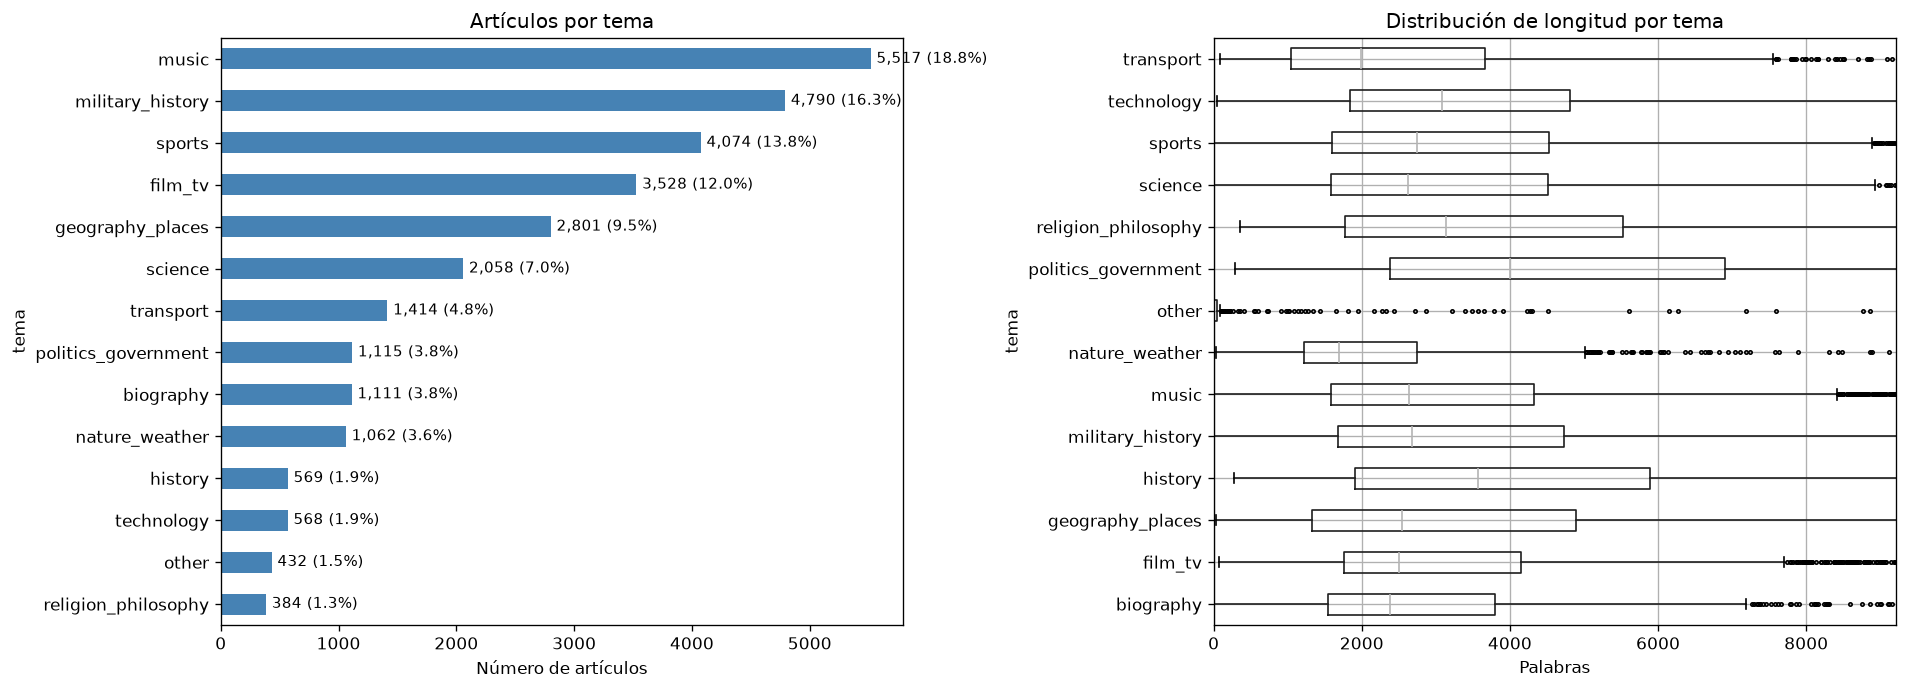

In [7]:
# Gráficas de temas
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Barplot de temas
ax = axes[0]
tema_counts.plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Número de artículos")
ax.set_title("Artículos por tema")
ax.invert_yaxis()
for i, (count, tema) in enumerate(zip(tema_counts.values, tema_counts.index)):
    ax.text(count + 50, i, f"{count:,} ({count/len(df)*100:.1f}%)", va="center", fontsize=9)

# Boxplot de palabras por tema
ax = axes[1]
df.boxplot(column="palabras", by="tema", ax=ax, vert=False, flierprops=dict(markersize=2))
ax.set_xlabel("Palabras")
ax.set_title("Distribución de longitud por tema")
ax.set_xlim(0, df["palabras"].quantile(0.95))
plt.suptitle("")

plt.tight_layout()
plt.show()

## 5. Estimación de costos

Estimamos tokens y costo del pipeline para ayudar a decidir el rango de tamaño óptimo.

In [8]:
# Estimación de tokens (~4 chars/token para inglés)
df["tokens_est"] = (df["caracteres"] / 4).astype(int)

# Pipeline: 3 traductores + 1 reviewer + 1 evaluador + metadata
# Por artículo, estimación conservadora de tokens totales:
#   Stage 1: 3 modelos × (prompt ≈ tokens_art + sistema) + (output ≈ tokens_art × 1.1)
#   Stage 2: prompt ≈ 3 × tokens_art + output ≈ tokens_art × 1.2
#   Stage 3: prompt ≈ 2 × tokens_art + output ≈ 200
#   Metadata: 2 llamadas × (prompt ≈ tokens_art + output ≈ 200)
# Total ≈ tokens_art × 12 (rough multiplier for full pipeline)

PIPELINE_MULTIPLIER = 12  # tokens totales / tokens del artículo

# Precios del .env actual (USD / 1M tokens promedio input+output)
COST_PER_1M_TOKENS = {
    "gpt-4.1-mini": (0.40 + 1.60) / 2,   # ~$1.00/M avg
    "gpt-4.1":      (2.00 + 8.00) / 2,    # ~$5.00/M avg (reviewer)
    "mistral":      (0.50 + 1.50) / 2,    # ~$1.00/M avg
    "ollama":       0.0,
}
# Weighted average cost: ~60% cheap models, ~30% reviewer (gpt-4.1), ~10% ollama
AVG_COST_PER_1M = 0.60 * 1.00 + 0.30 * 5.00 + 0.10 * 0.0  # $2.10/M tokens

df["costo_est_usd"] = df["tokens_est"] * PIPELINE_MULTIPLIER * AVG_COST_PER_1M / 1_000_000

print("ESTIMACIÓN DE COSTOS POR RANGO")
print("=" * 80)
cost_by_range = df.groupby("rango_palabras", observed=False).agg(
    articulos=("id", "count"),
    tokens_total=("tokens_est", "sum"),
    costo_total=("costo_est_usd", "sum"),
    costo_medio=("costo_est_usd", "mean"),
).reset_index()
cost_by_range["tokens_total"] = cost_by_range["tokens_total"].map(lambda x: f"{x:,.0f}")
cost_by_range["costo_total"] = cost_by_range["costo_total"].map(lambda x: f"${x:,.2f}")
cost_by_range["costo_medio"] = cost_by_range["costo_medio"].map(lambda x: f"${x:,.4f}")
print(cost_by_range.to_string(index=False))

print(f"\n{'─' * 80}")
print(f"Costo estimado TOTAL (todos los artículos): ${df['costo_est_usd'].sum():,.2f} USD")
print(f"Costo estimado promedio por artículo:       ${df['costo_est_usd'].mean():,.4f} USD")

ESTIMACIÓN DE COSTOS POR RANGO
rango_palabras  articulos tokens_total costo_total costo_medio
          <100        510       12,918       $0.33     $0.0006
       100-300        119       29,683       $0.75     $0.0063
       300-500        230      121,947       $3.07     $0.0134
        500-1K       2116    2,226,388      $56.10     $0.0265
         1K-2K       7973   15,746,299     $396.81     $0.0498
         2K-5K      12333   51,947,237   $1,309.07     $0.1061
        5K-10K       5032   45,837,780   $1,155.11     $0.2296
       10K-20K       1092   18,355,177     $462.55     $0.4236
       20K-50K         18      550,707      $13.88     $0.7710
          50K+          0            0       $0.00        $nan

────────────────────────────────────────────────────────────────────────────────
Costo estimado TOTAL (todos los artículos): $3,397.67 USD
Costo estimado promedio por artículo:       $0.1155 USD


## 6. Selección de 1,000 artículos

### Estrategia: muestreo estratificado por tema y tamaño

**Criterios de filtrado:**
- Descartar artículos con **< 1000 palabras** (stubs, poco contexto para traducción)
- Descartar artículos con **> 10,000 palabras** (muy costosos, riesgo de truncamiento)
- Esto deja un rango útil de **1K–10K palabras**

**Criterios de muestreo (1,000 artículos):**
- Muestreo **proporcional por tema** (mantener la distribución temática del corpus)
- Dentro de cada tema, muestreo **estratificado por tamaño** (bins: pequeño, mediano, grande)
- Esto garantiza diversidad tanto temática como de longitud

In [9]:
# ── Parámetros de selección (ajustables) ──
MIN_PALABRAS = 1_000
MAX_PALABRAS = 10_000
N_SELECCION = 1000
SEED = 42

# Filtrar rango útil
df_filtrado = df[(df["palabras"] >= MIN_PALABRAS) & (df["palabras"] <= MAX_PALABRAS)].copy()
print(f"Artículos en rango [{MIN_PALABRAS:,}–{MAX_PALABRAS:,}] palabras: {len(df_filtrado):,} / {len(df):,}")
print(f"Descartados: {len(df) - len(df_filtrado):,} ({(len(df) - len(df_filtrado)) / len(df) * 100:.1f}%)")
print()

# Bins de tamaño dentro del rango
size_bins = [MIN_PALABRAS, 2000, 4000, 5000, 8000, MAX_PALABRAS + 1]
size_labels = ["pequeño (1K-2K)", "mediano (2K-4K)", "medio-grande (4K-5K)",
               "grande (5K-8K)", "muy grande (8K-10K)"]
df_filtrado["bin_tamaño"] = pd.cut(df_filtrado["palabras"], bins=size_bins, labels=size_labels, right=False)

# Distribución de lo filtrado
print("Distribución del pool filtrado:")
print("─" * 50)
for tema in sorted(df_filtrado["tema"].unique()):
    n = len(df_filtrado[df_filtrado["tema"] == tema])
    print(f"  {tema:<25} {n:>5,}  ({n/len(df_filtrado)*100:>5.1f}%)")

Artículos en rango [1,000–10,000] palabras: 25,338 / 29,423
Descartados: 4,085 (13.9%)

Distribución del pool filtrado:
──────────────────────────────────────────────────
  biography                 1,007  (  4.0%)
  film_tv                   3,326  ( 13.1%)
  geography_places          2,216  (  8.7%)
  history                     485  (  1.9%)
  military_history          4,280  ( 16.9%)
  music                     4,910  ( 19.4%)
  nature_weather              928  (  3.7%)
  other                        36  (  0.1%)
  politics_government         962  (  3.8%)
  religion_philosophy         337  (  1.3%)
  science                   1,829  (  7.2%)
  sports                    3,474  ( 13.7%)
  technology                  493  (  1.9%)
  transport                 1,055  (  4.2%)


In [10]:
# Muestreo estratificado: proporcional por tema, dentro de cada tema por tamaño
rng = np.random.default_rng(SEED)

# Calcular cuota por tema (proporcional)
tema_fracs = df_filtrado["tema"].value_counts(normalize=True)
tema_cuotas = (tema_fracs * N_SELECCION).round().astype(int)
# Ajustar si la suma no da exacto
diff = N_SELECCION - tema_cuotas.sum()
if diff != 0:
    # Agregar/quitar del tema más grande
    tema_cuotas.iloc[0] += diff

print("Cuotas por tema:")
print("─" * 50)
for tema, cuota in tema_cuotas.items():
    pool = len(df_filtrado[df_filtrado["tema"] == tema])
    print(f"  {tema:<25} {cuota:>4} / {pool:>5,} disponibles")
print(f"  {'TOTAL':<25} {tema_cuotas.sum():>4}")

# Ejecutar muestreo
seleccionados = []
for tema, cuota in tema_cuotas.items():
    pool_tema = df_filtrado[df_filtrado["tema"] == tema]
    if len(pool_tema) <= cuota:
        seleccionados.append(pool_tema)
        continue

    # Estratificar por tamaño dentro del tema
    muestras_tema = []
    bin_counts = pool_tema["bin_tamaño"].value_counts()
    bin_fracs = bin_counts / bin_counts.sum()
    bin_cuotas = (bin_fracs * cuota).round().astype(int)
    # Ajustar
    diff_bin = cuota - bin_cuotas.sum()
    if diff_bin != 0:
        bin_cuotas.iloc[0] += diff_bin

    for bin_label, bin_cuota in bin_cuotas.items():
        pool_bin = pool_tema[pool_tema["bin_tamaño"] == bin_label]
        n_sample = min(bin_cuota, len(pool_bin))
        if n_sample > 0:
            muestra = pool_bin.sample(n=n_sample, random_state=SEED)
            muestras_tema.append(muestra)

    if muestras_tema:
        tema_df = pd.concat(muestras_tema)
        # Si nos faltaron por bins vacíos, completar del pool general del tema
        if len(tema_df) < cuota:
            faltantes = cuota - len(tema_df)
            restantes = pool_tema[~pool_tema.index.isin(tema_df.index)]
            extra = restantes.sample(n=min(faltantes, len(restantes)), random_state=SEED)
            tema_df = pd.concat([tema_df, extra])
        seleccionados.append(tema_df)

df_seleccion = pd.concat(seleccionados).reset_index(drop=True)
print(f"\nSeleccionados: {len(df_seleccion):,} artículos")

Cuotas por tema:
──────────────────────────────────────────────────
  music                      195 / 4,910 disponibles
  military_history           169 / 4,280 disponibles
  sports                     137 / 3,474 disponibles
  film_tv                    131 / 3,326 disponibles
  geography_places            87 / 2,216 disponibles
  science                     72 / 1,829 disponibles
  transport                   42 / 1,055 disponibles
  biography                   40 / 1,007 disponibles
  politics_government         38 /   962 disponibles
  nature_weather              37 /   928 disponibles
  technology                  19 /   493 disponibles
  history                     19 /   485 disponibles
  religion_philosophy         13 /   337 disponibles
  other                        1 /    36 disponibles
  TOTAL                     1000

Seleccionados: 1,000 artículos


## 7. Validación de la selección

Verificamos que la selección sea representativa comparando distribuciones.

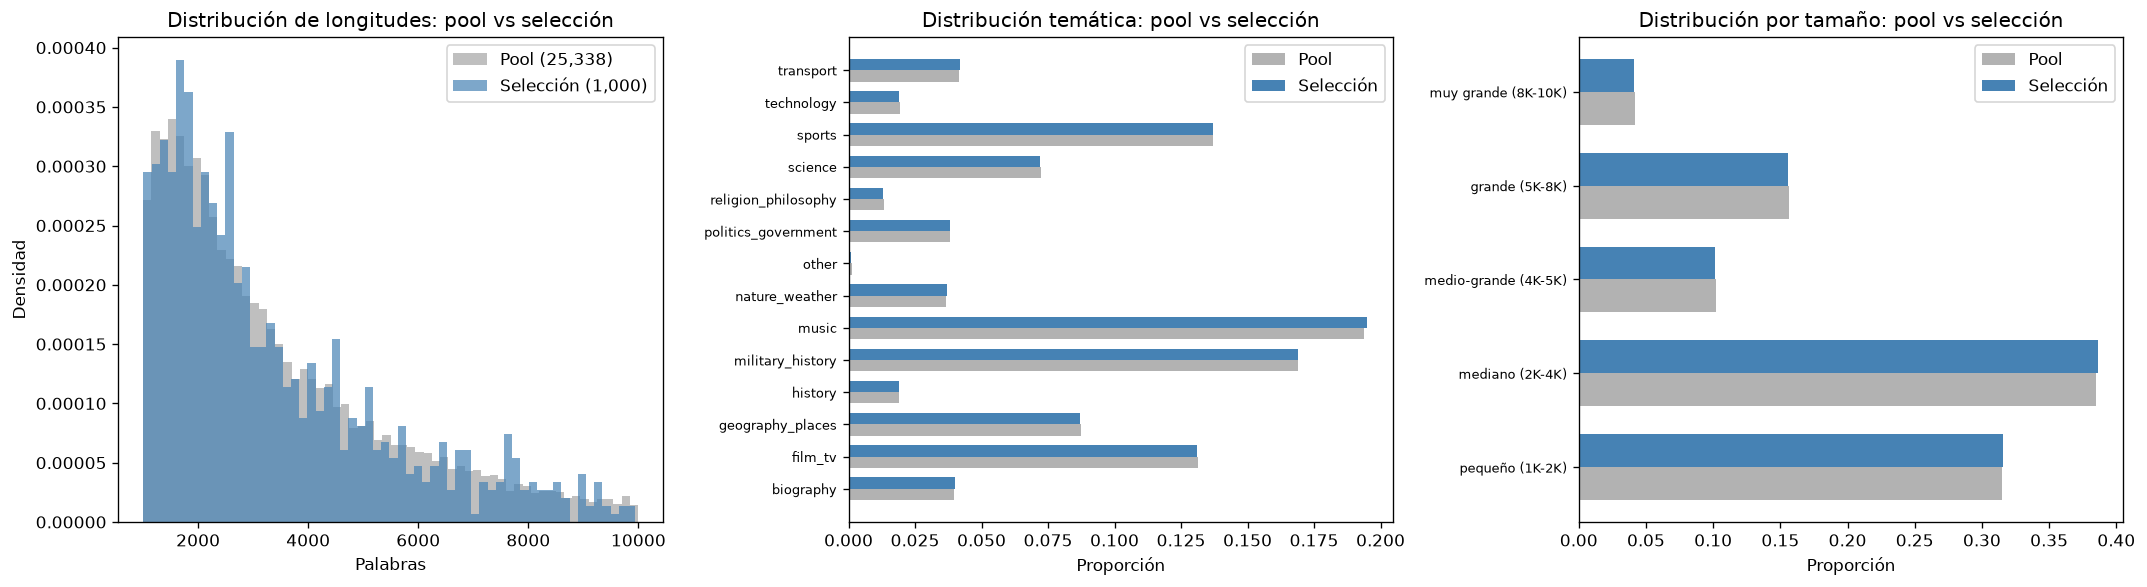


RESUMEN DE LA SELECCIÓN
Artículos seleccionados:   1,000
Palabras totales:          3,348,793
Tokens estimados:          4,448,532
Costo estimado pipeline:   $112.10 USD
Rango de palabras:         [1,007 – 9,942]
Temas representados:       14
Media palabras/artículo:   3,349
Mediana palabras/artículo: 2,656


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Comparar distribución de palabras
ax = axes[0]
ax.hist(df_filtrado["palabras"], bins=60, alpha=0.5, label=f"Pool ({len(df_filtrado):,})", color="gray", density=True)
ax.hist(df_seleccion["palabras"], bins=60, alpha=0.7, label=f"Selección ({len(df_seleccion):,})", color="steelblue", density=True)
ax.set_xlabel("Palabras")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de longitudes: pool vs selección")
ax.legend()

# Comparar distribución de temas
ax = axes[1]
pool_temas = df_filtrado["tema"].value_counts(normalize=True).sort_index()
sel_temas = df_seleccion["tema"].value_counts(normalize=True).sort_index()
x = np.arange(len(pool_temas))
w = 0.35
ax.barh(x - w/2, pool_temas.values, w, label="Pool", color="gray", alpha=0.6)
ax.barh(x + w/2, sel_temas.reindex(pool_temas.index, fill_value=0).values, w, label="Selección", color="steelblue")
ax.set_yticks(x)
ax.set_yticklabels(pool_temas.index, fontsize=8)
ax.set_xlabel("Proporción")
ax.set_title("Distribución temática: pool vs selección")
ax.legend()

# Distribución por bin de tamaño
ax = axes[2]
pool_bins = df_filtrado["bin_tamaño"].value_counts(normalize=True).sort_index()
sel_bins = df_seleccion["bin_tamaño"].value_counts(normalize=True).sort_index()
x = np.arange(len(pool_bins))
ax.barh(x - w/2, pool_bins.values, w, label="Pool", color="gray", alpha=0.6)
ax.barh(x + w/2, sel_bins.reindex(pool_bins.index, fill_value=0).values, w, label="Selección", color="steelblue")
ax.set_yticks(x)
ax.set_yticklabels(pool_bins.index, fontsize=8)
ax.set_xlabel("Proporción")
ax.set_title("Distribución por tamaño: pool vs selección")
ax.legend()

plt.tight_layout()
plt.show()

# Estadísticas resumen
print("\nRESUMEN DE LA SELECCIÓN")
print("=" * 60)
print(f"Artículos seleccionados:   {len(df_seleccion):,}")
print(f"Palabras totales:          {df_seleccion['palabras'].sum():,}")
print(f"Tokens estimados:          {df_seleccion['tokens_est'].sum():,}")
print(f"Costo estimado pipeline:   ${df_seleccion['costo_est_usd'].sum():,.2f} USD")
print(f"Rango de palabras:         [{df_seleccion['palabras'].min():,} – {df_seleccion['palabras'].max():,}]")
print(f"Temas representados:       {df_seleccion['tema'].nunique()}")
print(f"Media palabras/artículo:   {df_seleccion['palabras'].mean():,.0f}")
print(f"Mediana palabras/artículo: {df_seleccion['palabras'].median():,.0f}")

## 8. Exportar archivo de artículos seleccionados

Genera un `.raw` con los 1,000 artículos seleccionados, listo para pasarlo al pipeline de traducción. También exporta un CSV con los metadatos de la selección.

In [12]:
# Exportar archivo .raw con los artículos seleccionados (ordenados por ID original)
df_seleccion_sorted = df_seleccion.sort_values("id")
ids_seleccionados = set(df_seleccion_sorted["id"].values)

OUTPUT_RAW = Path("../data/WikiText/wikitext-103-raw.wiki.train.selected_1000.raw")
OUTPUT_CSV = Path("wikitext_seleccion_1000.csv")

# Escribir .raw — preservar formato WikiText original:
#   - Cada artículo empieza con " = Título = " (espacio antes del =)
#   - Separación entre artículos: línea vacía + salto de línea
with open(OUTPUT_RAW, "w", encoding="utf-8") as f:
    for i, art_id in enumerate(df_seleccion_sorted["id"]):
        art_text = articulos_raw[art_id - 1]
        # Restaurar espacio inicial si el título lo perdió por strip()
        if art_text.startswith("= ") and not art_text.startswith(" = "):
            art_text = " " + art_text
        if i > 0:
            f.write("\n\n")
        f.write(art_text)
    f.write("\n")

size_mb = OUTPUT_RAW.stat().st_size / (1024**2)
print(f"Archivo .raw exportado: {OUTPUT_RAW}")
print(f"  Tamaño: {size_mb:.1f} MB")
print(f"  Artículos: {len(df_seleccion_sorted):,}")

# Verificar que el split funciona correctamente
import subprocess
count = subprocess.run(
    ["grep", "-c", "^ = [^=]", str(OUTPUT_RAW)],
    capture_output=True, text=True
).stdout.strip()
print(f"  Headers nivel 1 detectados: {count} (esperado: {len(df_seleccion_sorted):,})")

# Exportar CSV con metadatos
cols_export = ["id", "titulo", "palabras", "caracteres", "secciones", "tema", "bin_tamaño", "tokens_est", "costo_est_usd"]
df_seleccion_sorted[cols_export].to_csv(OUTPUT_CSV, index=False, encoding="utf-8")
print(f"\nCSV de metadatos: {OUTPUT_CSV}")
print(f"\nListo para ejecutar:")
print(f"  python3 agente_wikitext.py -i {OUTPUT_RAW}")

Archivo .raw exportado: ../data/WikiText/wikitext-103-raw.wiki.train.selected_1000.raw
  Tamaño: 17.0 MB
  Artículos: 1,000
  Headers nivel 1 detectados: 1013 (esperado: 1,000)

CSV de metadatos: wikitext_seleccion_1000.csv

Listo para ejecutar:
  python3 agente_wikitext.py -i ../data/WikiText/wikitext-103-raw.wiki.train.selected_1000.raw
